# Heart murmur model analysis

1. Plot the saved Random Forest's feature importance.
2. Compare a correctly detected murmur with one the CNN missed.
3. Train a scaled Logistic Regression baseline on the same 56 features as the Random Forest.
4. Compare patient-level ROC curves for all three models.
5. Compare Random Forest and Logistic Regression ROC-AUC in a separate figure.

Place this notebook in `notebooks/` and select the **DS_env** kernel. The first plot needs the saved Random Forest model. The other sections need the project's raw WAV files, recording splits, and saved window predictions. If the split CSV is missing, run these from the repo root:

```cmd
python -m src.preprocessing.create_indexes
python -m src.preprocessing.split_patients
```

Run the notebook from the repo root or its `notebooks/` folder. Figures go to `reports/figures/additional_analysis/`, and results go to `outputs/additional_analysis/`.

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
if not (root / "src" / "config.py").is_file():
    raise FileNotFoundError("Open this notebook from the repo root or notebooks folder.")
sys.path.insert(0, str(root))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

plt.style.use("dark_background")

from src.config import LABELS, WINDOW_SECONDS
from src.evaluation.aggregate_patients import KEYS, PROBS, aggregate_patients, metrics
from src.models.data_utils import CACHE_DIR, SEED, SPLIT_NAMES, cache_settings, encode_labels, make_predictions_table
from src.models.features import RF_FEATURE_NAMES, extract_log_mel, extract_rf_features
from src.preprocessing.audio_preprocessing import iter_recording_windows

outputs = root / "outputs"
FIGURES_DIR = root / "reports" / "figures" / "additional_analysis"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
destination = outputs / "additional_analysis"
destination.mkdir(parents=True, exist_ok=True)

## 1. Random Forest feature importance

The bars show how much each feature reduced impurity in the saved forest's splits. Related features can share importance. The chart summarizes the forest's overall behavior and cannot explain an individual diagnosis.

Interpretation: the feature-importance plot shows which summary features most strongly influence the forest's decisions overall. Taller bars mean the model relied more on those features to separate murmur and non-murmur sounds, but they do not explain every individual patient case.

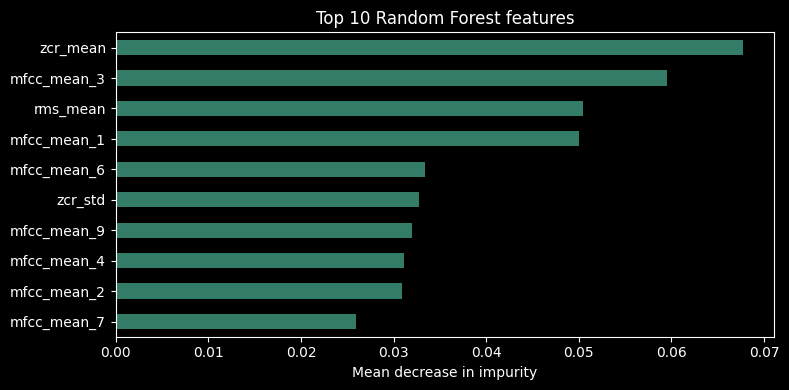

,Importance
zcr_mean,0.067699
mfcc_mean_3,0.059472
rms_mean,0.050483
mfcc_mean_1,0.049972
mfcc_mean_6,0.033367
zcr_std,0.032791
mfcc_mean_9,0.031999
mfcc_mean_4,0.031087
mfcc_mean_2,0.030870
mfcc_mean_7,0.025957


In [2]:
forest = joblib.load(outputs / "rf_model.joblib")
importance = pd.Series(forest.feature_importances_, index=RF_FEATURE_NAMES)
top_features = importance.nlargest(10).sort_values()
ax = top_features.plot.barh(figsize=(8, 4), color="#327C68")
ax.set(title="Top 10 Random Forest features", xlabel="Mean decrease in impurity")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "rf_top10_feature_importance.png", dpi=180)
plt.show()
display(top_features.sort_values(ascending=False).rename("Importance").to_frame())

## 2. One detected murmur and one missed murmur

Choose two test patients labeled Present. The CNN called one Present and the other Absent. For a consistent comparison, show the first full four-second window at the same chest location for both patients. Choose the examples by sorted patient ID and a fixed location order. This shows two example inputs. The patient prediction uses all of each patient's recordings.

Interpretation: this pair of examples shows the model's decision boundary in action. The correctly detected case reflects a pattern the model recognizes, while the missed case helps highlight where signal quality, timing, or waveform shape may be causing confusion.

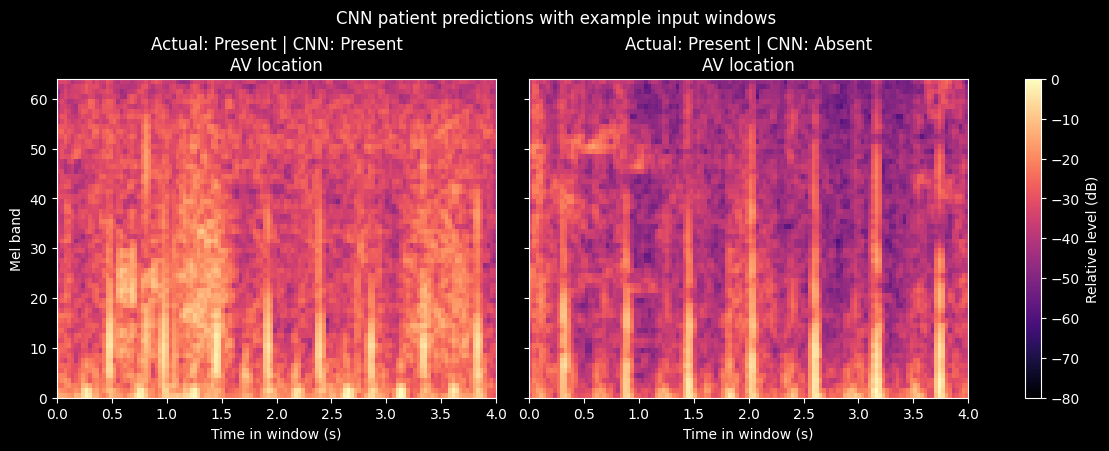

Patient 29045 | Recording 29045_AV | window 0 | Patient Present probability 0.470
Patient 13918 | Recording 13918_AV | window 0 | Patient Present probability 0.211


In [3]:
recordings = pd.read_csv(root / "data/processed/recording_splits.csv", dtype={"patient_id": str})
cnn = pd.read_csv(outputs / "cnn_window_predictions.csv", dtype={"subject_id": str})
rf = pd.read_csv(outputs / "rf_window_predictions.csv", dtype={"subject_id": str})

def window_index(table):
    return table[KEYS + ["split", "true_label"]].sort_values(KEYS).reset_index(drop=True)

pd.testing.assert_frame_equal(window_index(cnn), window_index(rf))
test_cnn = cnn[cnn["split"].eq("test")]
patients = aggregate_patients(test_cnn, "recording_mean")
present = patients[patients["true_label"].eq("Present")]

recordings = recordings.assign(
    recording_id=recordings["recording"].map(lambda name: Path(name).stem)
)
saved_test_recordings = test_cnn[["subject_id", "recording_id"]].drop_duplicates()
candidates = recordings[recordings["split"].eq("test")].merge(
    saved_test_recordings, left_on=["patient_id", "recording_id"],
    right_on=["subject_id", "recording_id"]
).merge(
    present[["subject_id", "pred_label", "prob_present"]],
    on="subject_id"
).sort_values(["patient_id", "recording_id"])

examples = []
for location in ["AV", "MV", "PV", "TV"]:
    pair = []
    for outcome in ["Present", "Absent"]:
        pool = candidates[candidates["location"].eq(location) & candidates["pred_label"].eq(outcome)]
        for _, row in pool.iterrows():
            first = next(iter_recording_windows(row.to_frame().T), None)
            if first is None:
                continue
            window, rate, meta = first
            if meta["valid_samples"] == len(window):
                pair.append((row, extract_log_mel(window, rate)))
                break
    if len(pair) == 2:
        examples = pair
        break

if not examples:
    raise ValueError("No detected/missed pair shares a chest location with full windows.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout="constrained")
for ax, (row, mel) in zip(axes, examples):
    image = ax.imshow(mel, origin="lower", aspect="auto", cmap="magma",
                      vmin=-80, vmax=0, extent=[0, WINDOW_SECONDS, 0, mel.shape[0]])
    ax.set(title=f"Actual: Present | CNN: {row['pred_label']}\n{row['location']} location",
           xlabel="Time in window (s)")
axes[0].set_ylabel("Mel band")
fig.colorbar(image, ax=axes, label="Relative level (dB)")
fig.suptitle("CNN patient predictions with example input windows")
fig.savefig(FIGURES_DIR / "cnn_detected_vs_missed.png", dpi=180)
plt.show()

for row, _ in examples:
    print(f"Patient {row['patient_id']} | Recording {row['recording_id']} | "
          f"window 0 | Patient Present probability {row['prob_present']:.3f}")

## 3. Logistic Regression baseline

Train Logistic Regression on the same audio summary features as Random Forest. Fit the scaler and model on training windows only. Keep class weighting balanced and use a fixed regularization setting (`C=1.0`). Evaluate each split separately using the same patient averaging as the other models.

Interpretation: the logistic-regression baseline tells us whether a simple linear decision rule can separate the classes nearly as well as the random forest. If the baseline performs much worse, the murmur signal depends more on nonlinear feature interactions than on a straightforward threshold pattern.

In [4]:
import json

settings_file = CACHE_DIR / "settings.json"
cached_windows = CACHE_DIR / "windows.csv"
cached_features = CACHE_DIR / "rf_features.npy"
if (settings_file.is_file() and cached_windows.is_file() and cached_features.is_file()
        and json.loads(settings_file.read_text()) == cache_settings()):
    windows = pd.read_csv(cached_windows, dtype={"subject_id": str})
    features = np.load(cached_features)
    print("Using cached Random Forest features.")
else:
    rows, feature_rows = [], []
    for i, (window, rate, meta) in enumerate(iter_recording_windows(recordings), start=1):
        rows.append({
            "subject_id": meta["patient_id"],
            "recording_id": Path(meta["recording"]).stem,
            "location": meta["location"],
            "window_idx": meta["window_idx"],
            "split": SPLIT_NAMES[meta["split"]],
            "true_label": meta["murmur_label"],
        })
        feature_rows.append(extract_rf_features(window[:meta["valid_samples"]], rate))
        if i % 2000 == 0:
            print(f"Prepared {i:,} windows")
    windows = pd.DataFrame(rows)
    features = np.stack(feature_rows)

pd.testing.assert_frame_equal(window_index(windows), window_index(rf))
assert features.shape == (len(windows), len(RF_FEATURE_NAMES))
assert np.isfinite(features).all()
assert windows.groupby("subject_id")["split"].nunique().eq(1).all()

train = windows["split"].eq("train").to_numpy()
y_train = encode_labels(windows.loc[train, "true_label"])
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED),
)
model.fit(features[train], y_train)
assert np.array_equal(model.classes_, np.arange(len(LABELS)))
logistic = make_predictions_table(windows, model.predict_proba(features))
logistic.to_csv(destination / "logistic_window_predictions.csv", index=False)

Using cached Random Forest features.


,Split,Model,Patients,Accuracy,Macro-F1,Present recall,Macro ROC-AUC
0,val,Random Forest,141,0.780,0.619,0.481,0.763
1,val,Original CNN,141,0.879,0.784,0.704,0.905
2,val,Logistic Regression,141,0.589,0.521,0.630,0.790
3,test,Random Forest,142,0.718,0.520,0.370,0.766
4,test,Original CNN,142,0.824,0.677,0.667,0.896
5,test,Logistic Regression,142,0.570,0.465,0.593,0.758


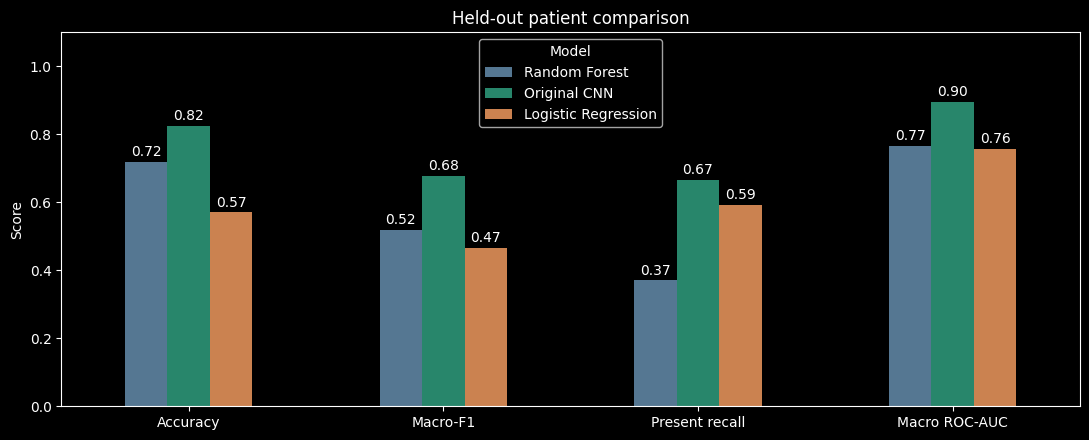

In [5]:
rows = []
for split in ["val", "test"]:
    for name, table in [("Random Forest", rf), ("Original CNN", cnn),
                        ("Logistic Regression", logistic)]:
        patient_predictions = aggregate_patients(table[table["split"].eq(split)], "recording_mean")
        scores = metrics(patient_predictions)
        targets = patient_predictions["true_label"].to_numpy()[:, None] == np.array(LABELS)
        rows.append({
            "Split": split,
            "Model": name,
            "Patients": scores["n_subjects"],
            "Accuracy": scores["accuracy"],
            "Macro-F1": scores["macro_f1"],
            "Present recall": scores["recall_present"],
            "Macro ROC-AUC": roc_auc_score(targets, patient_predictions[PROBS], average="macro"),
        })

results = pd.DataFrame(rows)
display(results.round(3))
results.to_csv(destination / "baseline_comparison.csv", index=False)

test = results[results["Split"].eq("test")].set_index("Model")
ax = test[["Accuracy", "Macro-F1", "Present recall", "Macro ROC-AUC"]].T.plot.bar(
    figsize=(11, 4.5), rot=0, ylim=(0, 1.10), color=["#557792", "#28866B", "#CB8250"]
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set(title="Held-out patient comparison", ylabel="Score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "baseline_comparison.png", dpi=180)
plt.show()

## 4. Patient-level ROC curves

Compare Random Forest, CNN, and Logistic Regression on the same held-out test patients. Treat each label as the positive class and the other two labels as negatives. Average window probabilities within recordings, then give each recording equal weight in the patient prediction.

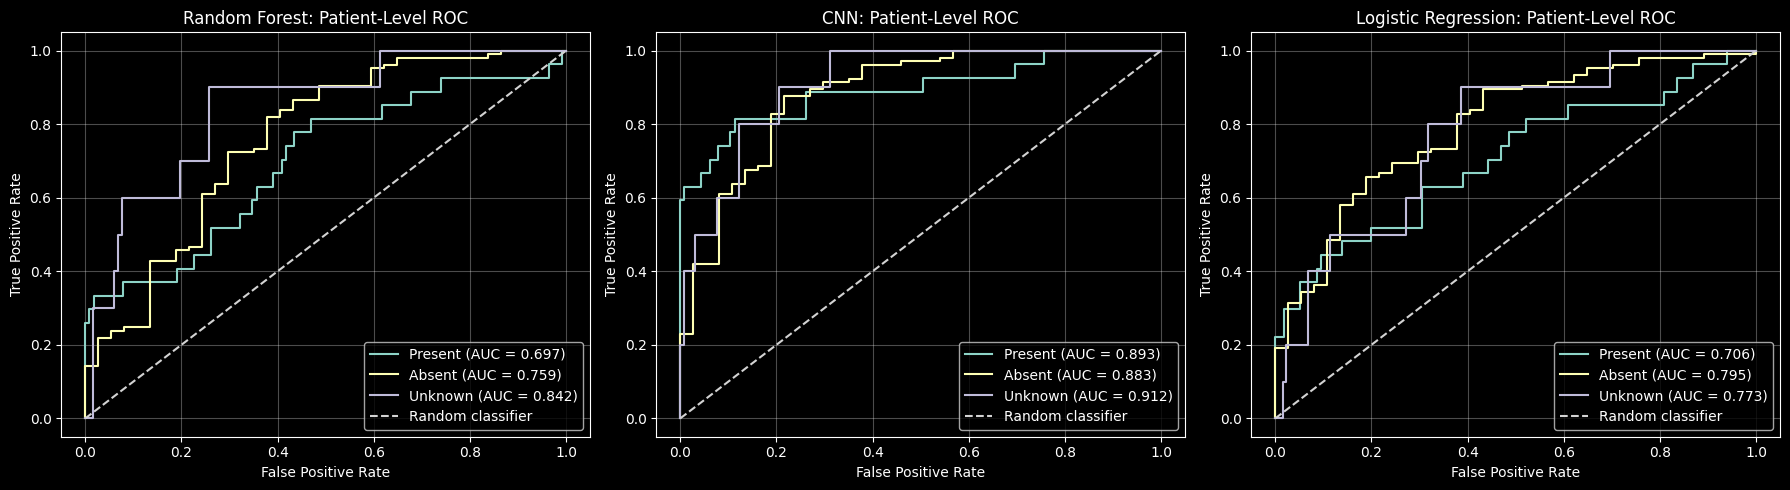

In [ ]:
from sklearn.metrics import roc_curve, auc

roc_predictions = {
    name: aggregate_patients(table.loc[table["split"].eq("test")], "recording_mean")
    for name, table in [("Random Forest", rf), ("CNN", cnn), ("Logistic Regression", logistic)]
}
fig, axes = plt.subplots(1, len(roc_predictions), figsize=(6 * len(roc_predictions), 5))
for ax, (model_name, predictions) in zip(axes, roc_predictions.items()):
    for label, probability_column in zip(LABELS, PROBS):
        fpr, tpr, _ = roc_curve(
            predictions["true_label"].eq(label),
            predictions[probability_column]
        )
        ax.plot(fpr, tpr, label=f"{label} (AUC = {auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], color="lightgray", linestyle="--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(model_name + ": Patient-Level ROC")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "patient_roc_curves.png", dpi=300)
fig.savefig(FIGURES_DIR.parent / "patient_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)

## 5. Random Forest versus Logistic Regression AUC

Compare the two feature-based classifiers on the same held-out test patients using the recording-weighted predictions above. Each panel shows class-specific ROC curves and AUCs; the title reports their macro average.

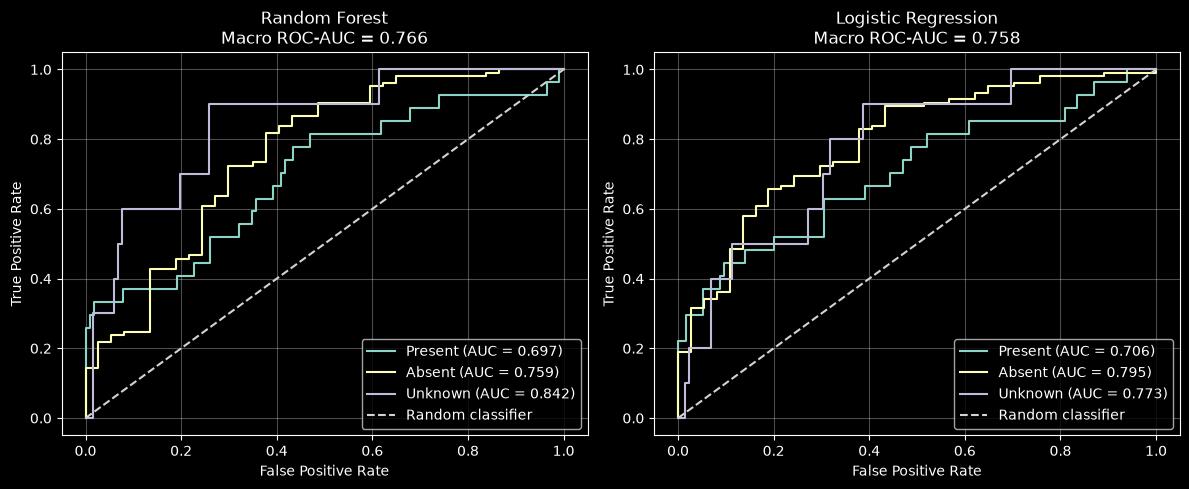

In [ ]:
from sklearn.metrics import roc_curve, auc

comparison_models = ["Random Forest", "Logistic Regression"]
reference_patients = (
    roc_predictions["Random Forest"][["subject_id", "true_label"]]
    .sort_values("subject_id").reset_index(drop=True)
)
for name in comparison_models:
    identities = (
        roc_predictions[name][["subject_id", "true_label"]]
        .sort_values("subject_id").reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(reference_patients, identities)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, comparison_models):
    patients = roc_predictions[name]
    class_aucs = []
    for label, probability_column in zip(LABELS, PROBS):
        fpr, tpr, _ = roc_curve(patients["true_label"].eq(label), patients[probability_column])
        class_auc = auc(fpr, tpr)
        class_aucs.append(class_auc)
        ax.plot(fpr, tpr, label=f"{label} (AUC = {class_auc:.3f})")
    ax.plot([0, 1], [0, 1], color="lightgray", linestyle="--", label="Random classifier")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name}\nMacro ROC-AUC = {np.mean(class_aucs):.3f}")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIGURES_DIR / "rf_vs_logistic_regression_roc_curves.png", dpi=300)
plt.show()
plt.close(fig)